# ДЗ 1. Прогнозирование продаж: анализ и предобработка временного ряда

Курс «Прогнозирование временных рядов и обработка сигналов».

Товар для анализа: **85099B** (JUMBO BAG RED RETROSPOT). На лекции разбирали 85123A, это другой товар.

Все методы лежат в `src/ts_tools.py`, здесь только вызовы функций и разбор результатов. Корень репозитория находится автоматически, ноутбук выполняется сверху вниз.

In [2]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ищем корень репозитория (там, где лежит src/ts_tools.py), откуда бы ни запустили ноутбук
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "ts_tools.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Не нашёл src/ts_tools.py. Откройте ноутбук из папки репозитория "
                            "и убедитесь, что папка src лежит рядом с ним.")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import ts_tools as T

from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 100
Path("figures").mkdir(exist_ok=True)


def show(name):
    """Сохраняем текущий график в figures/ (для README) и показываем."""
    plt.savefig(f"figures/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


results = {}   # сюда складываем числа для итоговых выводов

## Шаг 1. Данные и формирование временного ряда

Если файла с данными нет, он скачается с UCI.

In [3]:
DATA_FILE = Path("data/Online Retail.xlsx")

if not DATA_FILE.exists():
    import io, urllib.request, zipfile
    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    with urllib.request.urlopen(url) as resp:
        zf = zipfile.ZipFile(io.BytesIO(resp.read()))
    name = [n for n in zf.namelist() if n.lower().endswith(".xlsx")][0]
    DATA_FILE.parent.mkdir(exist_ok=True)
    DATA_FILE.write_bytes(zf.read(name))

df = T.load_retail(DATA_FILE)
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550,"17,850.000",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750,"17,850.000",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390,"17,850.000",United Kingdom


In [4]:
df.info()
print()
print("Пропуски по столбцам:")
print(df.isna().sum())
print()
print("Доля счетов-возвратов (InvoiceNo на C):", round(df["InvoiceNo"].str.startswith("C").mean(), 4))
print("Строк с Quantity <= 0:", int((df["Quantity"] <= 0).sum()))
print("Период данных:", df["InvoiceDate"].min(), "-", df["InvoiceDate"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Пропуски по столбцам:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Доля счетов-возвратов (InvoiceNo на C): 0.0171
Строк с Quantity <= 0: 10624
Период данных: 2010

Для ряда нужны три поля: `StockCode` (отбор товара), `InvoiceDate` (дата) и `Quantity` (показатель продаж, штуки). `InvoiceNo` нужен, чтобы убрать возвраты: счета, начинающиеся на C, это отмены с отрицательным количеством, в продажи они не входят.

Посмотрим на самые частые товары и выберем не тот, что был на лекции.

In [5]:
top_codes = df["StockCode"].value_counts().head(10).index
top = (df[df["StockCode"].isin(top_codes)]
       .groupby("StockCode")
       .agg(строк=("InvoiceNo", "size"),
            штук=("Quantity", "sum"),
            описание=("Description", lambda x: x.mode().iat[0]))
       .sort_values("строк", ascending=False))
top

,строк,штук,описание
StockCode,,,
85123A,2313,38830,WHITE HANGING HEART T-LIGHT HOLDER
22423,2203,12980,REGENCY CAKESTAND 3 TIER
85099B,2159,47363,JUMBO BAG RED RETROSPOT
47566,1727,18022,PARTY BUNTING
20725,1639,18979,LUNCH BAG RED RETROSPOT
84879,1502,36221,ASSORTED COLOUR BIRD ORNAMENT
22720,1477,7286,SET OF 3 CAKE TINS PANTRY DESIGN
22197,1476,56450,POPCORN HOLDER
21212,1385,36039,PACK OF 72 RETROSPOT CAKE CASES


In [6]:
STOCK = "85099B"   # на лекции был 85123A

print(df.loc[df["StockCode"] == STOCK, "Description"].value_counts(dropna=False))

prod = T.select_product(df, STOCK)
print("\nТранзакций с продажами товара:", len(prod))
print("Первая и последняя продажа:", prod["InvoiceDate"].min(), "/", prod["InvoiceDate"].max())

Description
JUMBO BAG RED RETROSPOT    2159
Name: count, dtype: int64

Транзакций с продажами товара: 2115
Первая и последняя продажа: 2010-12-01 09:57:00 / 2011-12-09 10:26:00


Показатель продаж: количество проданных штук (`Quantity`). Выручку не берём, чтобы цена не примешивалась к спросу.

Агрегируем по дням, неделям (неделя заканчивается в воскресенье) и месяцам. Сначала получаем сырые ряды: **период без единой транзакции остаётся NaN, а не нулём**. Что это такое на самом деле, решим на шаге 2. Неполные периоды по краям (данные начинаются 1 декабря 2010 и заканчиваются 9 декабря 2011 посреди дня) отрезаем, иначе первая и последняя неделя/месяц занижены просто из-за обрезки.

In [7]:
data_start, data_end = df["InvoiceDate"].min(), df["InvoiceDate"].max()
open_days = T.shop_open_days(df)

FREQS = {"D": ("день", "D"), "W": ("неделя", "W-SUN"), "MS": ("месяц", "M")}
raw = {}
for f, (label, pf) in FREQS.items():
    s = T.trim_to_sales_span(T.aggregate(prod, f))
    raw[f] = T.drop_partial_edges(s, data_start, data_end, pf)

summary = pd.DataFrame({
    FREQS[f][0]: {"наблюдений": len(s), "начало": s.index[0].date(),
                  "конец": s.index[-1].date(), "пустых периодов (NaN)": int(s.isna().sum())}
    for f, s in raw.items()
}).T
summary

,наблюдений,начало,конец,пустых периодов (NaN)
день,373,2010-12-01,2011-12-08,73
неделя,52,2010-12-12,2011-12-04,1
месяц,12,2010-12-01,2011-11-01,0


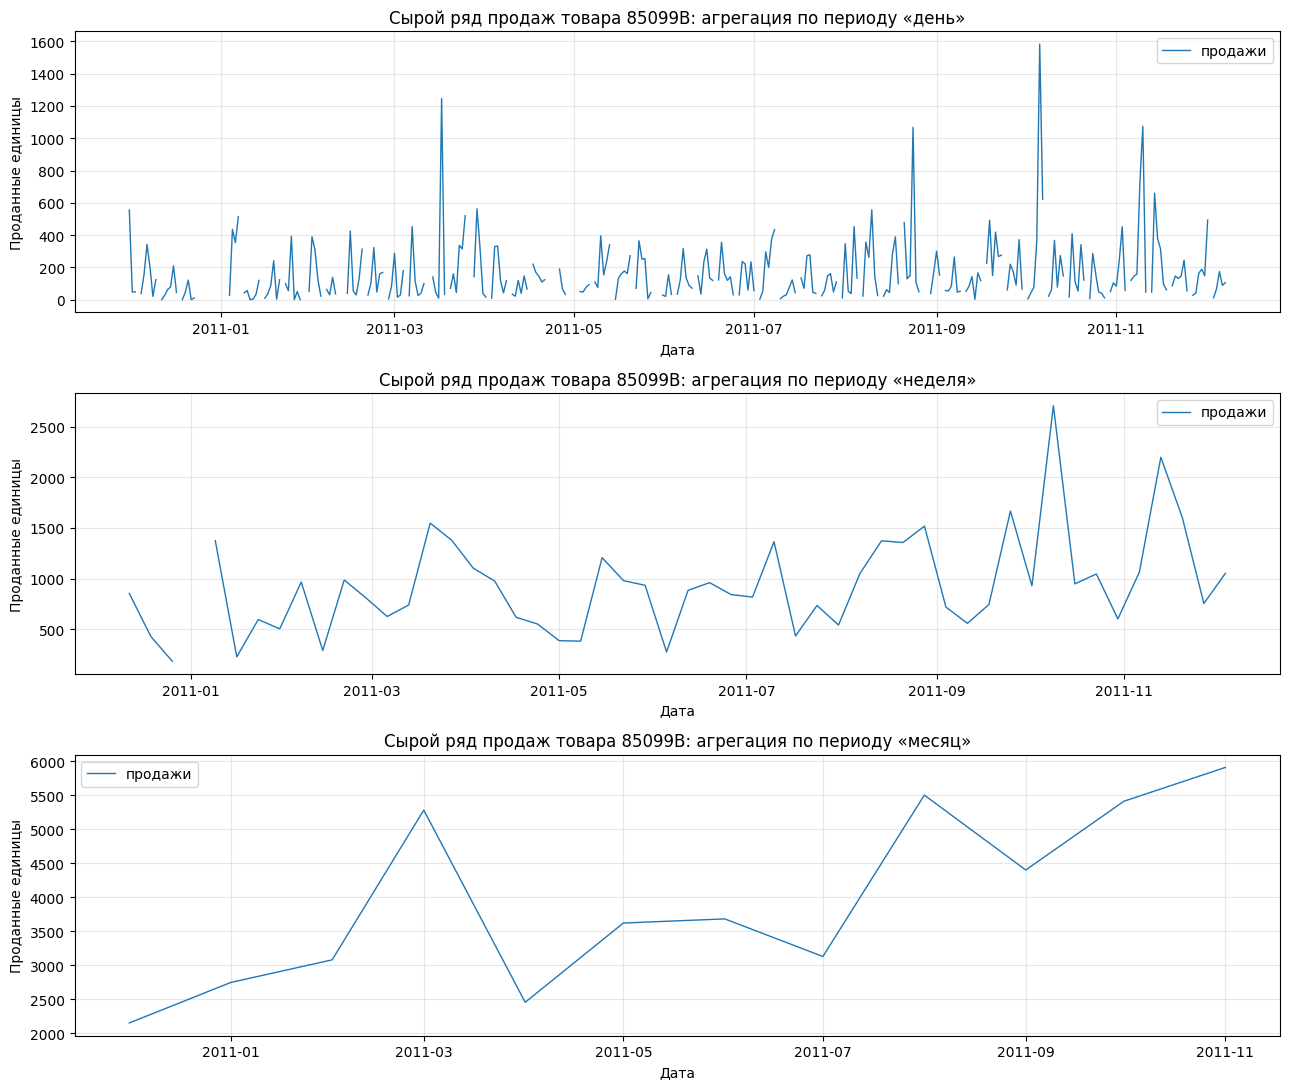

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, (f, s) in zip(axes, raw.items()):
    T.plot_series(s, f"Сырой ряд продаж товара {STOCK}: агрегация по периоду «{FREQS[f][0]}»",
                  "Проданные единицы", ax=ax)
fig.tight_layout()
show("01_raw_all_freq")

**Что получилось.** Дневной ряд содержит 373 дня (с 1 декабря 2010 по 8 декабря 2011), недельный 52 недели, месячный 12 месяцев. Последний день данных, 9 декабря, обрывается в 12:50, поэтому я его отбросил вместе с неполными неделей и месяцем, иначе последняя точка была бы занижена просто из-за обрезки. По той же причине недельный ряд начинается с недели 6-12 декабря 2010, а месячный идёт с декабря 2010 по ноябрь 2011.

Суммы по трём рядам немного разные (в дневном 48 463 штуки, в недельном 48 112, в месячном 47 373). Это не ошибка: ряды покрывают разные отрезки времени, а в недельном ещё есть одна интерполированная неделя (см. ниже).

**Первое впечатление по графикам.** Продажи растут к осени: месячные значения поднимаются с примерно 2 150 штук в декабре 2010 до 5 900 в ноябре 2011, с пиком около 5 300 в марте и провалом в апреле. На дневном графике много коротких «иголок» (март, август, октябрь, ноябрь), а на недельном самый высокий пик это начало октября (около 2 700 штук).

## Шаг 2. Качество данных

### Пропуски

Главный вопрос: пустой день означает «товар не покупали» или «магазин в этот день не работал»? Это разные вещи. Первое действительно ноль продаж, второе не наблюдение вообще, и ставить туда ноль нельзя. Различить можно по всему датасету: если в день нет ни одной транзакции ни по одному товару, магазин не работал.

In [9]:
rep = T.missing_report(raw["D"])
print(f"Дневной ряд: {rep['n_missing']} пустых дней из {rep['n_total']} ({rep['share_missing']:.1%})")
print("Число отдельных пустых отрезков:", len(rep["runs"]))
print("Самые длинные пустые отрезки:")
print(rep["runs"].sort_values("length", ascending=False).head(5).to_string(index=False))

print("\nНа какие дни недели приходятся пустые дни:")
print(T.weekday_gaps(raw["D"]).to_string())

zero_days, closed_days = T.split_empty_days(raw["D"], open_days)
print(f"\nМагазин работал, товар не купили (настоящий ноль): {len(zero_days)} дней")
print(f"Магазин не работал вообще (не наблюдение):         {len(closed_days)} дней")
wd_ru = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
closed_by_wd = closed_days.dayofweek.value_counts().sort_values(ascending=False)
print("Закрытые дни по дням недели:", ", ".join(f"{wd_ru[i]}: {n}" for i, n in closed_by_wd.items()))

Дневной ряд: 73 пустых дней из 373 (19.6%)
Число отдельных пустых отрезков: 56
Самые длинные пустые отрезки:
     start        end  length
2010-12-24 2011-01-03      11
2011-04-22 2011-04-25       4
2011-03-12 2011-03-13       2
2011-01-29 2011-01-30       2
2011-04-29 2011-04-30       2

На какие дни недели приходятся пустые дни:
Пн     6
Вт     1
Ср     1
Чт     2
Пт     4
Сб    53
Вс     6

Магазин работал, товар не купили (настоящий ноль): 4 дней
Магазин не работал вообще (не наблюдение):         69 дней
Закрытые дни по дням недели: Сб: 53, Пн: 6, Пт: 4, Вс: 3, Вт: 1, Ср: 1, Чт: 1


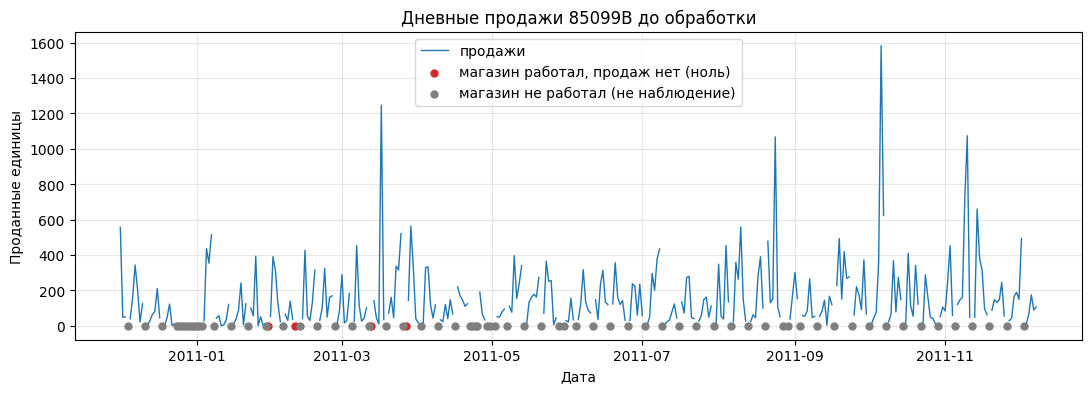

In [10]:
ax = T.plot_series(raw["D"], f"Дневные продажи {STOCK} до обработки", "Проданные единицы",
                   marks=[(pd.Series(0, index=zero_days), "магазин работал, продаж нет (ноль)", "tab:red"),
                          (pd.Series(0, index=closed_days), "магазин не работал (не наблюдение)", "tab:gray")])
show("02_daily_gaps")

**Пропуски.** Пустых дней 73 из 373 (19,6 %), но почти все они объясняются тем, что магазин в эти дни не работал: 69 из 73 пустых дней это дни, когда в датасете нет ни одной транзакции ни по одному товару. 53 из них субботы (каждая суббота за весь период, по субботам магазин не торгует). Остальные 16 это праздничные перерывы. Самые длинные: 24 декабря - 3 января (11 дней) и 22-25 апреля (4 дня), что похоже на рождественские каникулы и пасхальные выходные. Это не нулевой спрос, а отсутствие наблюдения, и нули туда ставить нельзя.

Настоящих нулей всего 4 (магазин работал, а товар не купили): три воскресенья и один четверг. Воскресенье в среднем самый слабый день (см. график по дням недели), так что нули там не удивляют.

Решение по пропускам: нули ставим только в дни, когда магазин работал. Дни без торговли из дневного ряда убираем, получается ряд на торговом календаре. Подстановка нулей в закрытые дни исказила бы картину: вышла бы искусственная «просадка» каждую неделю.

Недельный и месячный ряды устроены проще: пустой период с работающим магазином это ноль, а период, где магазин не работал совсем, интерполируется. В данных такая одна неделя (27 декабря 2010 - 2 января 2011), она целиком попадает в рождественский перерыв.

In [11]:
daily = T.to_trading_calendar(raw["D"], open_days)

weekly = T.fill_zero_if_open(raw["W"], open_days, "W-SUN")
print("Недель, где магазин не работал совсем (остались NaN):", int(weekly.isna().sum()))
if weekly.isna().any():
    weekly = T.fill_missing(weekly, "interpolate")

monthly = T.fill_zero_if_open(raw["MS"], open_days, "M")
print("Месяцев, где магазин не работал совсем (остались NaN):", int(monthly.isna().sum()))
if monthly.isna().any():
    monthly = T.fill_missing(monthly, "interpolate")

PERIOD_D = daily.index.dayofweek.nunique()   # длина торговой недели в днях
print(f"\nДневной ряд на торговом календаре: {len(daily)} наблюдений, "
      f"из них нулевых {(daily == 0).sum()}, торговая неделя = {PERIOD_D} дн.")

results.update(n_daily=len(daily), n_weekly=len(weekly), n_monthly=len(monthly),
               n_zero_days=len(zero_days), n_closed_days=len(closed_days),
               closed_by_wd={int(k): int(v) for k, v in closed_by_wd.items()}, period_d=PERIOD_D)

Недель, где магазин не работал совсем (остались NaN): 1
Месяцев, где магазин не работал совсем (остались NaN): 0

Дневной ряд на торговом календаре: 304 наблюдений, из них нулевых 4, торговая неделя = 6 дн.


### Выбросы

Один метод для продаж ненадёжен, ряд скошенный и с тяжёлым хвостом. Сравним три:

1. **IQR (правило Тьюки)**: простое, но не знает про тренд и сезонность.
2. **MAD (модифицированный z-score)**: на медиане, устойчивее к самим выбросам.
3. **Остаток STL**: сначала убираем тренд и недельный цикл, потом ищем аномалии в остатке.

In [12]:
m_iqr, (lo, hi) = T.iqr_outliers(daily)
m_mad, z_mad = T.mad_outliers(daily)
m_stl, resid = T.stl_residual_outliers(daily, PERIOD_D)

flags = pd.DataFrame({"IQR": m_iqr, "MAD": m_mad, "STL-остаток": m_stl})
flags["голосов"] = flags.sum(axis=1)

print(f"Граница IQR: [{lo:.0f}; {hi:.0f}]")
print("Сколько точек отметил каждый метод:")
print(flags[["IQR", "MAD", "STL-остаток"]].sum().to_string())
print("\nТочки, отмеченные минимум двумя методами:")
cand = flags[flags["голосов"] >= 2].assign(продано=daily).sort_values("продано", ascending=False)
print(cand[["продано", "голосов"]].to_string())

Граница IQR: [-222; 486]
Сколько точек отметил каждый метод:
IQR            14
MAD            15
STL-остаток    60

Точки, отмеченные минимум двумя методами:
             продано  голосов
2011-10-06 1,583.000        3
2011-03-17 1,246.000        3
2011-11-10 1,074.000        3
2011-08-24 1,068.000        3
2011-11-09   725.000        3
2011-11-14   660.000        3
2011-10-07   623.000        3
2011-03-29   563.000        3
2011-08-10   557.000        3
2010-12-01   556.000        3
2011-03-25   521.000        3
2011-01-07   514.000        3
2011-09-19   493.000        3
2011-12-02   493.000        3
2011-08-21   478.000        2


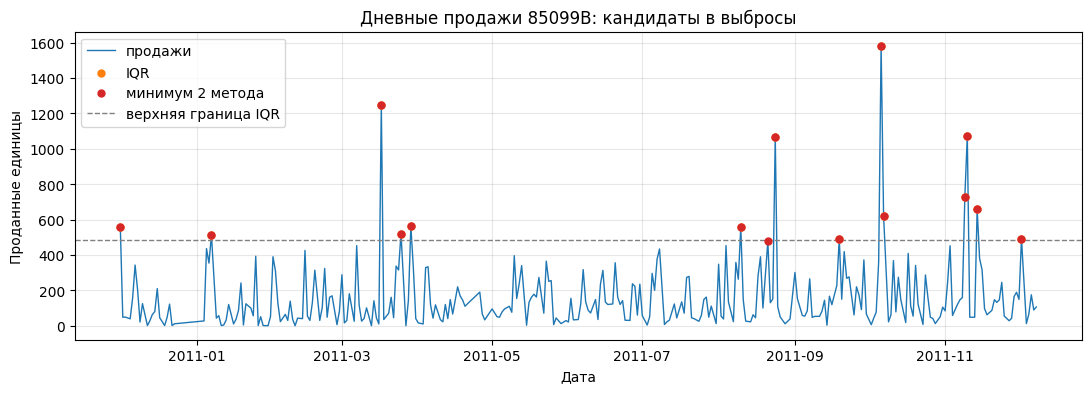

In [13]:
ax = T.plot_series(daily, f"Дневные продажи {STOCK}: кандидаты в выбросы", "Проданные единицы",
                   marks=[(daily[m_iqr], "IQR", "tab:orange"),
                          (daily[flags["голосов"] >= 2], "минимум 2 метода", "tab:red")])
ax.axhline(hi, ls="--", c="gray", lw=1, label="верхняя граница IQR")
ax.legend()
show("03_outliers")

**Выбросы.** Методы дали разное число точек: IQR 14 (граница 486 штук), MAD 15, остаток STL 60. Шестьдесят это каждая пятая точка, так что все отметки STL выбросами считать нельзя: после вычитания тренда и недельного цикла остаток всё равно с тяжёлым хвостом, а порог в три робастные сигмы получается узким. Поэтому ориентируюсь на согласие методов: минимум два метода отметили 15 дней.

Все 14 точек IQR отметили и два других метода (поэтому на графике оранжевые точки IQR закрыты красными). Пятнадцатая, 21 августа 2011 (478 штук), под границу IQR не попадает, но это воскресенье, когда продаётся мало, а STL как раз учитывает день недели. Самые крупные дни это 6 октября (1583 штуки), 17 марта (1246) и 10 ноября (1074). Кстати, 1 декабря 2010 (556 штук) попадает в список тоже, это первый день данных.

Прежде чем что-то менять, смотрим, из чего состоят самые большие дни. Если это один огромный счёт, это реальный оптовый заказ (датасет оптовый), а не ошибка ввода.

In [14]:
for d in cand.index[:3]:
    print("Дата:", d.date(), "| продано за день:", int(daily[d]))
    print(T.inspect_day(prod, d).to_string(index=False))
    print()

Дата: 2011-10-06 | продано за день: 1583
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   569815      1000      1.790  15,838.000 United Kingdom
   569857       200      1.950  12,939.000 United Kingdom
   569740       140      1.790  15,769.000 United Kingdom
   569839       100      1.790  15,769.000 United Kingdom
   569844        20      2.080  12,626.000        Germany

Дата: 2011-03-17 | продано за день: 1246
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   546789      1200      1.650  15,769.000 United Kingdom
   546899        30      1.650  14,298.000 United Kingdom
   546786        10      1.950  16,523.000 United Kingdom
   546896         3      4.130         NaN United Kingdom
   546884         1      4.130         NaN United Kingdom

Дата: 2011-11-10 | продано за день: 1074
InvoiceNo  Quantity  UnitPrice  CustomerID        Country
   575582      1000      1.790  16,986.000 United Kingdom
   575683        30      2.080  17,389.000 United Kingdom
   57

Смотрим на состав самых больших дней. Во всех трёх случаях день «делает» один счёт на круглое число штук: 1000 из 1583 (6 октября), 1200 из 1246 (17 марта) и 1000 из 1074 (10 ноября). Это похоже на обычные оптовые заказы одного покупателя (датасет оптовый). Цена за штуку нормальная (1,65-1,79), количество положительное, а возвраты и отмены мы ещё при отборе товара выкинули. Признаков ошибки ввода нет.

Решение по выбросам: **не удаляю**. Это фактические продажи, пусть и крупные, а удаление занизило бы объём спроса и исказило ряд. Нужно только помнить, что такие пики вызваны единичными заказами, а не общим всплеском спроса, и предсказать их по истории нельзя.

Чтобы проверить, что выводы не держатся на нескольких днях, делаю вторую версию ряда, где значения ограничены сверху по «дальней» границе Тьюки (k = 3). На обеих версиях проверяю стационарность (шаг 5), остальные шаги считаю по исходному ряду.

Верхняя граница (k=3): 751. Изменено точек: 4 из 304


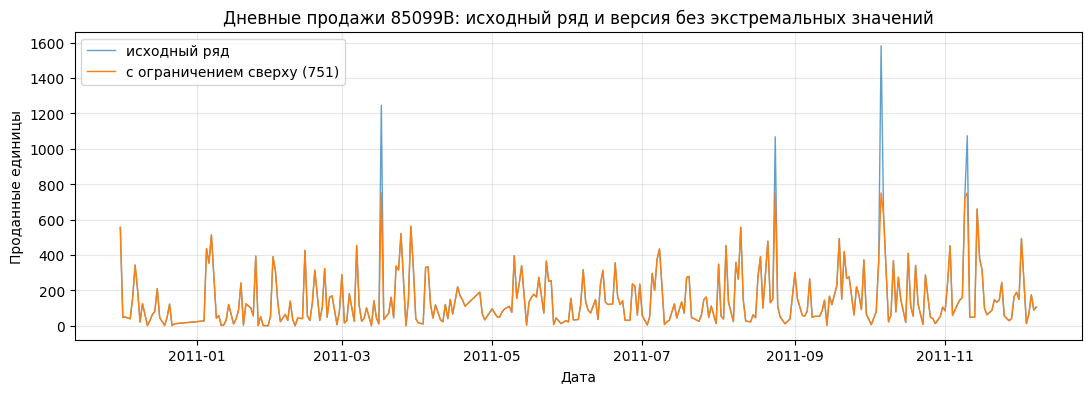

In [15]:
_, (lo3, hi3) = T.iqr_outliers(daily, k=3)
daily_w = T.winsorize(daily, lo=0, hi=hi3)

n_changed = int((daily_w != daily).sum())
print(f"Верхняя граница (k=3): {hi3:.0f}. Изменено точек: {n_changed} из {len(daily)}")

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, lw=1, label="исходный ряд", alpha=0.7)
ax.plot(daily_w.index, daily_w.values, lw=1, label=f"с ограничением сверху ({hi3:.0f})")
ax.set_title(f"Дневные продажи {STOCK}: исходный ряд и версия без экстремальных значений")
ax.set_xlabel("Дата"); ax.set_ylabel("Проданные единицы"); ax.grid(alpha=0.3); ax.legend()
show("04_winsorized")

results.update(outliers_iqr=int(m_iqr.sum()), outliers_mad=int(m_mad.sum()),
               outliers_stl=int(m_stl.sum()), outliers_2plus=int((flags["голосов"] >= 2).sum()),
               winsor_changed=n_changed, winsor_hi=float(hi3))

Ограничение сверху по 751 штуке затронуло только 4 дня из 304: это четыре самых больших значения (1583, 1246, 1074 и 1068). Остальной ряд не изменился. Эта версия нужна как проверка: если вывод одинаков на обеих, он не держится на четырёх днях.

## Шаг 3. Визуальный и описательный анализ

In [16]:
series = {"день": daily, "неделя": weekly, "месяц": monthly}
desc = pd.DataFrame({k: T.describe_series(v) for k, v in series.items()})
desc

,день,неделя,месяц
count,304.000,52.000,12.000
mean,159.418,925.240,"3,947.750"
std,189.207,483.680,"1,310.255"
min,0.000,181.000,"2,152.000"
25%,43.000,598.500,"2,996.750"
50%,105.500,867.500,"3,651.500"
75%,220.000,"1,073.000","5,314.500"
max,"1,583.000","2,709.000","5,909.000"
median,105.500,867.500,"3,651.500"
skew,3.237,1.285,0.233


Что значат нестандартные строки таблицы: `cv` это std/mean (разброс относительно уровня, больше 1 значит очень рваный ряд), `skew` показывает скошенность вправо (редкие крупные заказы), `adi` это среднее число периодов между продажами (1 значит продажи в каждом периоде), `cv2_nonzero` квадрат коэффициента вариации по ненулевым значениям. По паре adi / cv² принято классифицировать спрос: гладкий, нерегулярный, прерывистый, комковатый.

In [17]:
d = desc["день"]
if d["adi"] < 1.32 and d["cv2_nonzero"] < 0.49:
    demand = "гладкий"
elif d["adi"] < 1.32:
    demand = "нерегулярный, продажи почти каждый день, но объёмы скачут"
elif d["cv2_nonzero"] < 0.49:
    demand = "прерывистый"
else:
    demand = "комковатый, редкие продажи и скачущие объёмы"
print(f"ADI = {d['adi']:.2f}, CV² = {d['cv2_nonzero']:.2f} -> тип спроса по Syntetos-Boylan: {demand}")
print(f"Скошенность дневных продаж: {d['skew']:.2f}, коэффициент вариации: {d['cv']:.2f}")
results.update(demand_type=demand, adi=float(d["adi"]), cv2=float(d["cv2_nonzero"]),
               cv_daily=float(d["cv"]), skew_daily=float(d["skew"]))

ADI = 1.01, CV² = 1.38 -> тип спроса по Syntetos-Boylan: нерегулярный, продажи почти каждый день, но объёмы скачут
Скошенность дневных продаж: 3.24, коэффициент вариации: 1.19


**Дневной ряд.** Среднее (159 штук) заметно выше медианы (106): распределение скошено вправо (скошенность 3,2, эксцесс 16) из-за редких крупных заказов. Стандартное отклонение (189) больше среднего, коэффициент вариации 1,19, то есть день ото дня продажи очень неровные. Половина дней укладывается в диапазон 43-220 штук, максимум 1583.

**Агрегация сглаживает ряд.** Коэффициент вариации падает с 1,19 (день) до 0,52 (неделя) и 0,33 (месяц), скошенность с 3,2 до 1,3 и 0,2: крупные заказы растворяются в сумме. Недельный и месячный ряды гораздо спокойнее дневного, но в месячном всего 12 точек.

**Тип спроса.** ADI = 1,01: товар продаётся почти каждый торговый день (нулевых дней 1,3 %), так что спрос не прерывистый. CV² = 1,38 больше порога 0,49, поэтому по классификации Syntetos-Boylan спрос «нерегулярный»: продажи регулярные, но размер заказа сильно меняется. Для прогноза это значит, что недельные суммы предсказать заметно проще, чем отдельные дни.

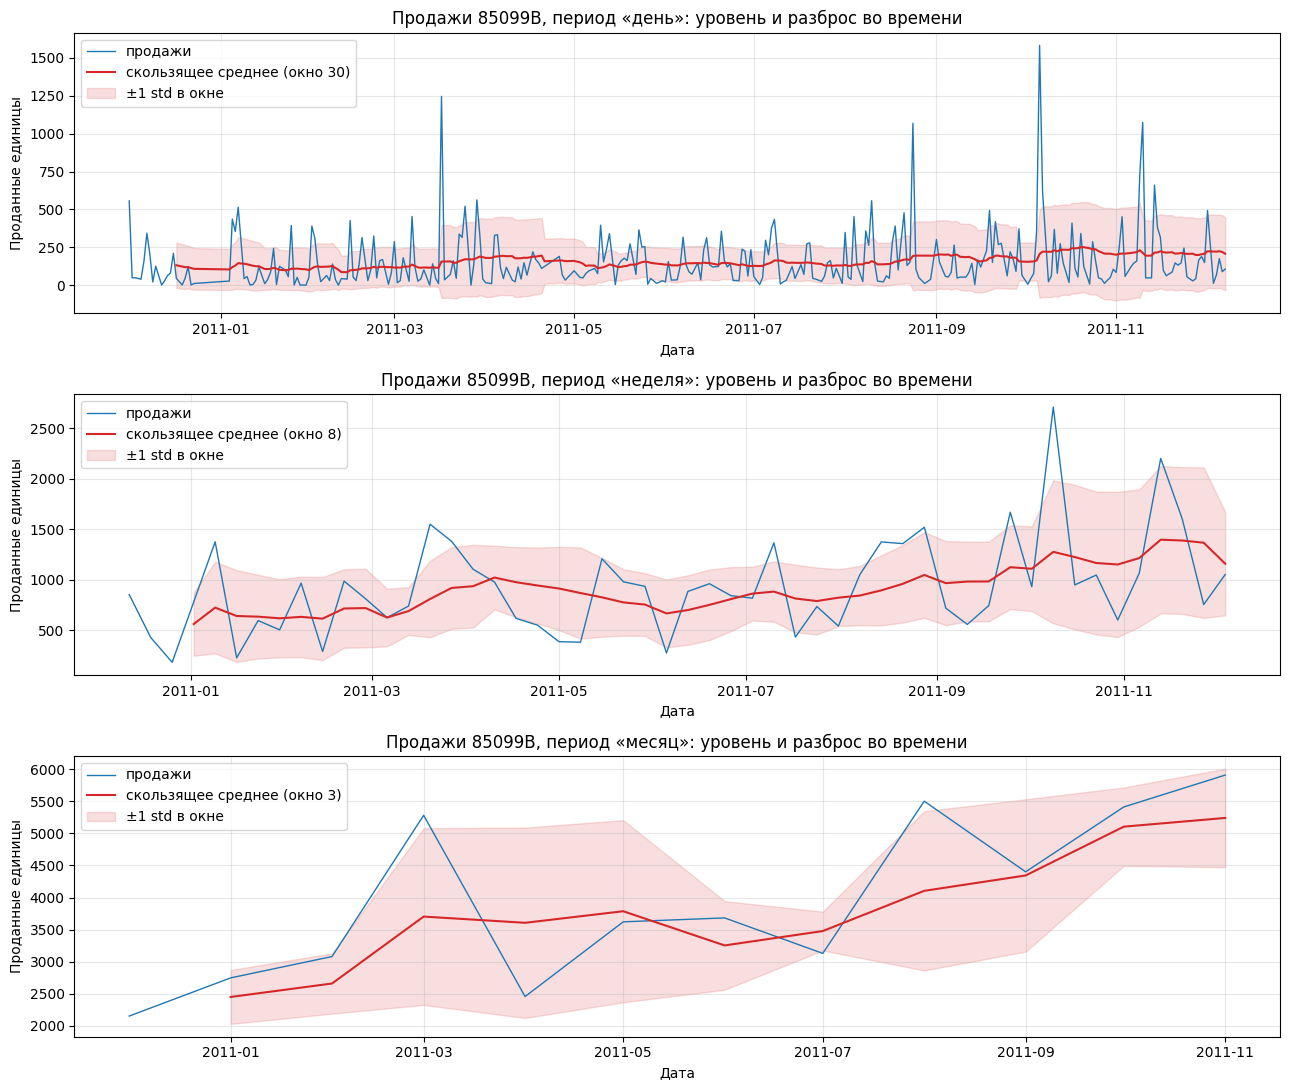

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, (name, s, w) in zip(axes, [("день", daily, 30), ("неделя", weekly, 8), ("месяц", monthly, 3)]):
    rs = T.rolling_stats(s, w)
    T.plot_series(s, f"Продажи {STOCK}, период «{name}»: уровень и разброс во времени",
                  "Проданные единицы", ax=ax)
    ax.plot(rs.index, rs["mean"], c="tab:red", label=f"скользящее среднее (окно {w})")
    ax.fill_between(rs.index, rs["mean"] - rs["std"], rs["mean"] + rs["std"],
                    color="tab:red", alpha=0.15, label="±1 std в окне")
    ax.legend()
fig.tight_layout()
show("05_level_and_spread")

In [19]:
print("Линейный тренд (наклон в единицах за период):")
for name, s in series.items():
    tr = T.trend_slope(s)
    print(f"  {name:7s} наклон {tr['slope']:+.3f}, p-value {tr['pvalue']:.3f}, R² {tr['r2']:.3f}")
    results[f"trend_{name}"] = tr

rs = T.rolling_stats(weekly, 8).dropna()
corr_ms = rs["mean"].corr(rs["std"])
print(f"\nКорреляция скользящего среднего и скользящего std (недели): {corr_ms:.2f}")
print("Чем выше она, тем сильнее разброс растёт вместе с уровнем, и тем оправданнее логарифм.")
results["corr_mean_std"] = float(corr_ms)

Линейный тренд (наклон в единицах за период):
  день    наклон +0.309, p-value 0.012, R² 0.021
  неделя  наклон +13.023, p-value 0.003, R² 0.166
  месяц   наклон +271.815, p-value 0.005, R² 0.559

Корреляция скользящего среднего и скользящего std (недели): 0.77
Чем выше она, тем сильнее разброс растёт вместе с уровнем, и тем оправданнее логарифм.


**Уровень.** Скользящее среднее растёт. В дневном ряду оно идёт с 100-140 штук зимой и весной до 200-250 осенью, в недельном с 600-700 до примерно 1 400 к ноябрю, в месячном с 2 500 до 5 200. Линейный тренд это подтверждает: +0,31 штуки за торговый день (p = 0,012), +13 за неделю (p = 0,003), +272 за месяц (p = 0,005). R² растёт с укрупнением периода (0,02; 0,17; 0,56): в дневных данных шум перекрывает тренд, а на месячных тренд объясняет больше половины дисперсии. Правда, месячных точек всего 12, а p-value обычной линейной регрессии для временных рядов оптимистичны, потому что остатки коррелированы.

**Оговорка.** Данные покрывают чуть больше года, и рост приходится на осень, предрождественский сезон розницы. Отличить настоящий долгосрочный тренд от годовой сезонности на таком ряду нельзя.

**Разброс.** Он тоже растёт вместе с уровнем: розовая полоса ±1 std осенью заметно шире, чем зимой. Корреляция скользящего среднего и скользящего std по неделям 0,77. Значит, дисперсия не постоянна (гетероскедастичность), и стабилизировать её, например логарифмом, имеет смысл.

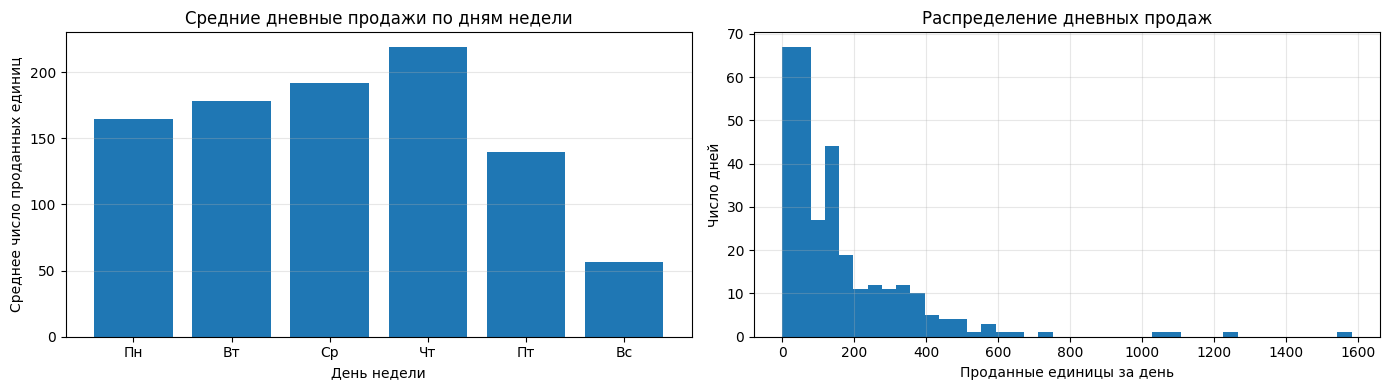

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

wd = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_wd = daily.groupby(daily.index.dayofweek).mean()
axes[0].bar([wd[i] for i in by_wd.index], by_wd.values)
axes[0].set_title("Средние дневные продажи по дням недели")
axes[0].set_xlabel("День недели"); axes[0].set_ylabel("Среднее число проданных единиц")
axes[0].grid(axis="y", alpha=0.3)

axes[1].hist(daily.values, bins=40)
axes[1].set_title("Распределение дневных продаж")
axes[1].set_xlabel("Проданные единицы за день"); axes[1].set_ylabel("Число дней")
axes[1].grid(alpha=0.3)
fig.tight_layout()
show("06_weekday_and_hist")

По дням недели самый слабый день воскресенье (в среднем около 56 штук), самый сильный четверг (около 220), пятница тоже ниже других будней (около 140). Различие воскресенья и четверга почти в четыре раза, это самая заметная недельная закономерность. Гистограмма показывает тот же перекос: большинство дней ниже 200 штук, длинный хвост до 1583 и всего четыре дня выше 1000.

## Шаг 4. Декомпозиция и сезонность

Выбираю **STL** с `robust=True`: он устойчив к выбросам (а они у нас есть и мы их не удаляли), допускает сезонность, которая медленно меняется, и работает с любым периодом. Классическую декомпозицию (`seasonal_decompose`) считаю для сравнения. Модель аддитивная: в ряду есть нули, а для мультипликативной они недопустимы. Если окажется, что разброс растёт вместе с уровнем, то на шаге 5 посмотрим, помогает ли логарифм.

Период: ряд идёт по торговым дням, значит неделя это не 7, а столько дней, сколько дней недели реально торгуют (`PERIOD_D`).

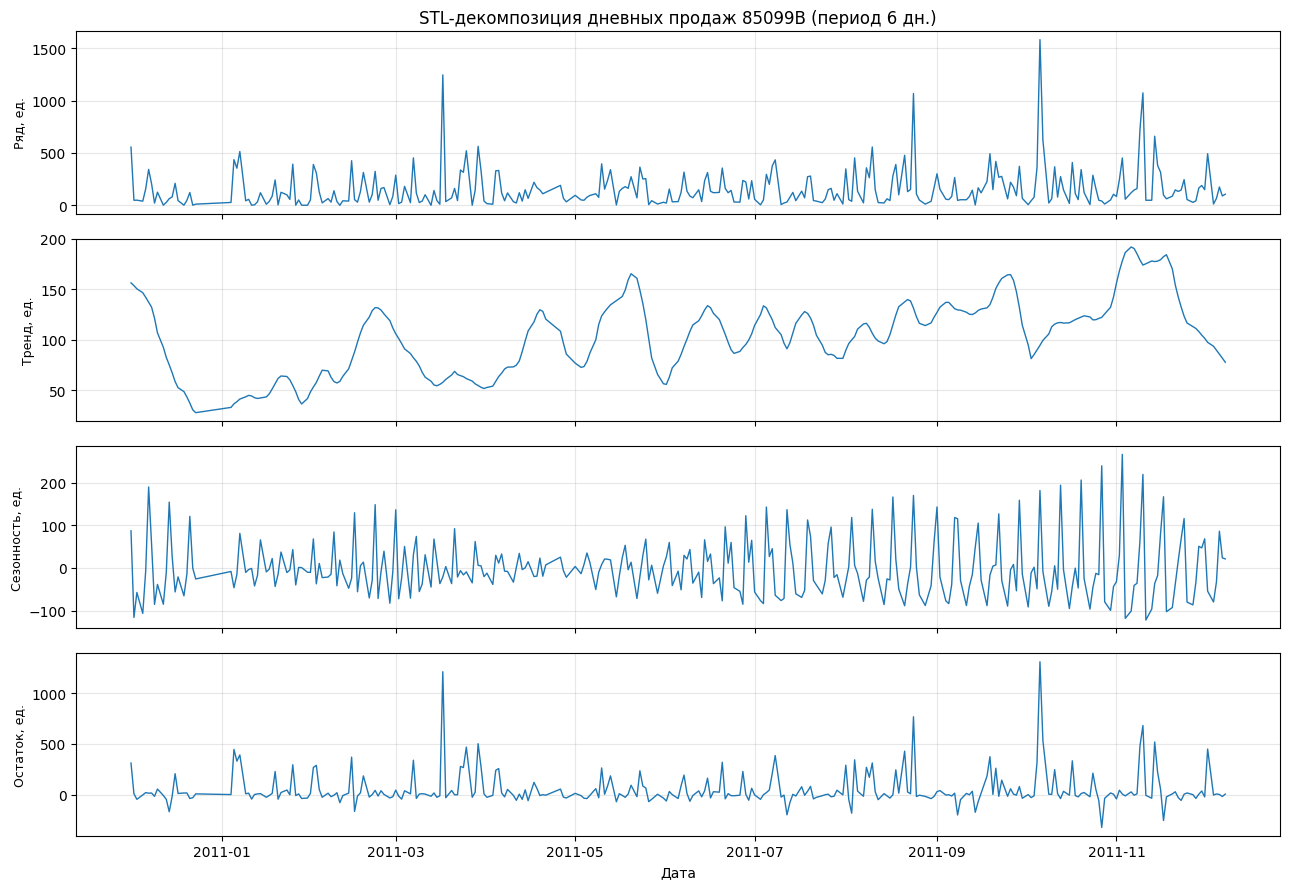

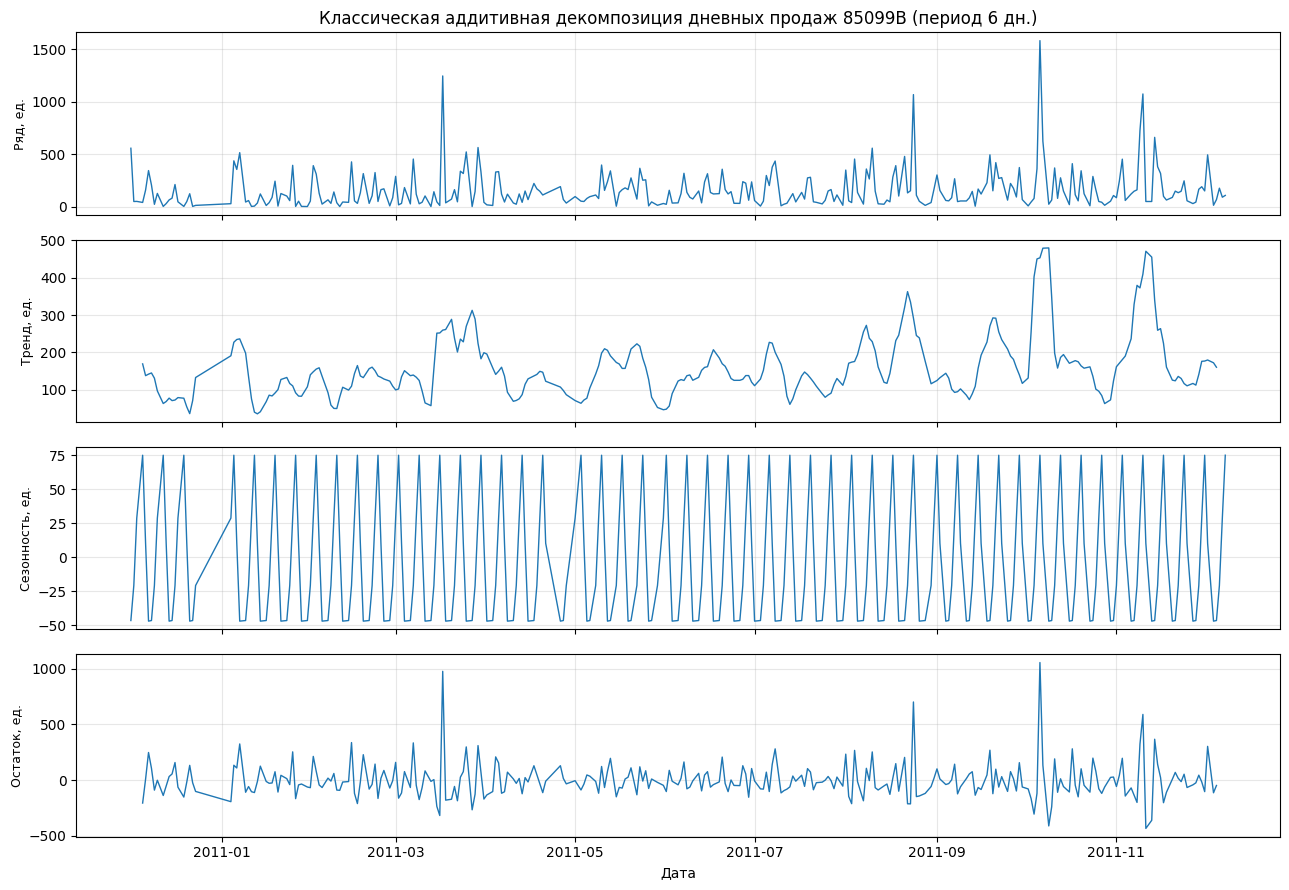

Сила компонент (0 - нет, 1 - доминирует), по Хайндману:
  STL:         сезонность 0.168, тренд 0.038
  классическая: сезонность 0.068, тренд 0.230


In [21]:
res_stl = T.decompose(daily, PERIOD_D, "stl")
res_cl = T.decompose(daily, PERIOD_D, "classic", model="additive")

T.plot_decomposition(res_stl, f"STL-декомпозиция дневных продаж {STOCK} (период {PERIOD_D} дн.)", "ед.")
show("07_stl")
T.plot_decomposition(res_cl, f"Классическая аддитивная декомпозиция дневных продаж {STOCK} (период {PERIOD_D} дн.)", "ед.")
show("08_classic")

st_stl = T.seasonal_strength(res_stl)
st_cl = T.seasonal_strength(res_cl)
print("Сила компонент (0 - нет, 1 - доминирует), по Хайндману:")
print(f"  STL:         сезонность {st_stl['seasonal_strength']:.3f}, тренд {st_stl['trend_strength']:.3f}")
print(f"  классическая: сезонность {st_cl['seasonal_strength']:.3f}, тренд {st_cl['trend_strength']:.3f}")

**Тренд.** В STL он плавный, но не монотонный: минимум около 30 штук в конце декабря 2010, максимум около 190 в начале ноября 2011, по пути локальные горбы (весной, в сентябре-ноябре), а в последние недели он снова опускается до 80 (на краях оценка менее надёжна). Общий наклон вверх согласуется с шагом 3.

**Сезонная составляющая.** Виден регулярный шестидневный профиль. Его размах меняется: зимой и весной он обычно в пределах ±50-100 штук, а осенью доходит до ±100-250. Размах растёт вместе с уровнем продаж, то есть недельный эффект ведёт себя скорее как процентный, а не как фиксированная добавка в штуках. STL это допускает, а в классической декомпозиции профиль один на весь ряд (примерно от -50 до +75).

**Остаток.** Почти весь около нуля с редкими всплесками: 17 марта (около 1200), 6 октября (около 1300), 24 августа и 10 ноября. Это те самые крупные заказы. Робастный STL не даёт им утащить за собой тренд и оставляет их в остатке. Классическая декомпозиция устроена иначе (обычное скользящее среднее), поэтому её тренд реагирует на всплески и получается «иголчатым» (до 480).

**Сила компонент.** По STL сезонность 0,17 и тренд 0,04, по классической 0,07 и 0,23 (0 значит, что компоненты нет, 1 что она доминирует). Сезонность в обоих случаях слабая. Разница по тренду (0,04 против 0,23) как раз следствие того, что классический тренд впитывает выбросы. Для этого ряда STL надёжнее.

Сезонность не объявляю по одной картинке. Проверяю четырьмя независимыми способами: сила сезонной компоненты STL, автокорреляция на лаге, равном периоду, критерий Краскела-Уоллиса по дням недели (H0: продажи во все дни недели распределены одинаково) и пики амплитудного спектра.

In [22]:
acf_vals, bound = T.acf_at_lags(daily, [1, PERIOD_D, 2 * PERIOD_D])
print(f"ACF на лагах (доверительная граница ±{bound:.3f}):")
print(acf_vals.round(3).to_string())

kw_stat, kw_p = T.weekday_kruskal(daily)
print(f"\nКраскел-Уоллис по дням недели: H = {kw_stat:.2f}, p-value = {kw_p:.4f}")

peaks = T.spectrum_peaks(daily, top=5)
print("\nТоп пиков амплитудного спектра (период в днях ряда):")
print(peaks.round(2).to_string(index=False))

signs = {
    f"сила сезонности STL > 0.3 ({st_stl['seasonal_strength']:.2f})": st_stl["seasonal_strength"] > 0.3,
    f"ACF на лаге {PERIOD_D} выше границы ({acf_vals[PERIOD_D]:.2f})": acf_vals[PERIOD_D] > bound,
    f"Краскел-Уоллис p < 0.05 ({kw_p:.3f})": kw_p < 0.05,
    f"пик спектра рядом с периодом {PERIOD_D}": bool((np.abs(peaks["period"] - PERIOD_D) < 0.5).any()),
}
print("\nПризнаки недельной сезонности:")
for k, v in signs.items():
    print(f"  [{'да' if v else 'нет'}] {k}")
n_yes = sum(signs.values())
weak = st_stl["seasonal_strength"] < 0.3   # сезонная компонента объясняет мало дисперсии
if n_yes >= 3 and not weak:
    season_verdict = "выражена"
elif n_yes >= 2:
    season_verdict = "статистически значима, но слабая" if weak else "умеренная"
else:
    season_verdict = "не подтверждена"
print(f"\nИтог: недельная сезонность {season_verdict} ({n_yes} из 4 признаков).")

results.update(season_strength=float(st_stl["seasonal_strength"]),
               trend_strength=float(st_stl["trend_strength"]),
               acf_period=float(acf_vals[PERIOD_D]), acf_bound=float(bound),
               kw_p=float(kw_p), season_verdict=season_verdict, season_signs=int(n_yes))

ACF на лагах (доверительная граница ±0.112):
1    0.158
6    0.120
12   0.038

Краскел-Уоллис по дням недели: H = 46.96, p-value = 0.0000

Топ пиков амплитудного спектра (период в днях ряда):
 period  amplitude
  5.960     59.580
  2.980     48.000
 12.670     45.050
 38.000     44.820
  5.430     44.450

Признаки недельной сезонности:
  [нет] сила сезонности STL > 0.3 (0.17)
  [да] ACF на лаге 6 выше границы (0.12)
  [да] Краскел-Уоллис p < 0.05 (0.000)
  [да] пик спектра рядом с периодом 6

Итог: недельная сезонность статистически значима, но слабая (3 из 4 признаков).


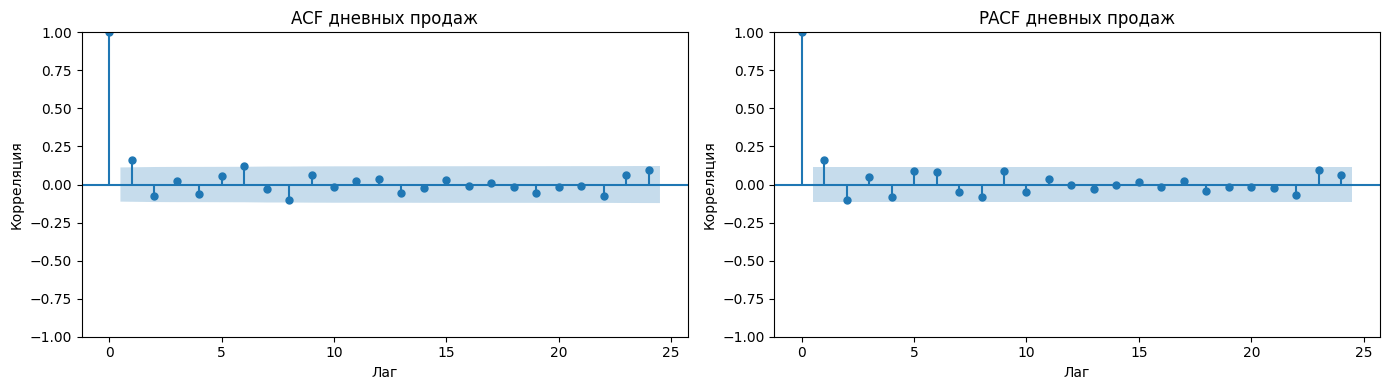

In [23]:
T.plot_acf_pacf(daily, lags=3 * PERIOD_D + 6, suffix="дневных продаж")
show("09_acf_pacf")

**Вывод о сезонности.** Три проверки из четырёх говорят «да», но с разной убедительностью. Критерий Краскела-Уоллиса убедителен (H = 47, p близко к нулю): продажи по дням недели действительно различаются, в основном воскресенье против остальных дней. В спектре самый высокий пик стоит на периоде 5,96, то есть на 6 днях (и его гармоника 2,98), но следующие пики (12,7; 38; 5,4 дня) лишь немного ниже, так что на 6 днях он резко не выделяется. ACF на лаге 6 равна 0,12 при границе 0,112, то есть едва выше, а на лаге 12 повторения нет (0,04). Сила сезонности STL всего 0,17.

Итого: недельная сезонность с периодом 6 торговых дней есть и статистически значима, но она объясняет малую часть изменчивости, большая часть колебаний это случайные заказы. Поэтому формулировка «статистически значимая, но слабая», а не «выраженная».

**ACF и PACF.** Корреляция соседних дней 0,16, дальше почти всё внутри доверительной полосы. Автокорреляций в ряду мало: он близок к шуму с небольшой памятью о вчерашнем дне и слабым недельным циклом. Медленного затухания ACF, которое бывает при тренде или единичном корне, нет.

### Годовая сезонность

Для годового цикла нужно хотя бы два полных периода, иначе его нельзя отделить от тренда. Проверим, что у нас есть.

In [24]:
for name, s, per in [("неделя", weekly, 52), ("месяц", monthly, 12)]:
    ok = len(s) >= 2 * per
    print(f"{name}: наблюдений {len(s)}, нужно минимум {2 * per} для периода {per} -> "
          f"{'можно оценивать' if ok else 'оценить нельзя'}")
results["yearly_testable"] = bool(len(weekly) >= 104)

неделя: наблюдений 52, нужно минимум 104 для периода 52 -> оценить нельзя
месяц: наблюдений 12, нужно минимум 24 для периода 12 -> оценить нельзя


Данных чуть больше года, поэтому **годовую сезонность по этим данным оценить нельзя**: рост продаж к осени нельзя отличить от тренда или разового события. Это ограничение датасета, а не отсутствие сезонности. На недельном и месячном рядах декомпозицию по годовому периоду не строю.

## Шаг 5. Стационарность

Используем два теста с противоположными нулевыми гипотезами:

* **ADF**: H0 – есть единичный корень (ряд нестационарен). p < 0.05 отвергает H0, значит ряд стационарен.
* **KPSS**: H0 – ряд стационарен. p < 0.05 отвергает H0, значит ряд нестационарен.

Уверенный вывод, когда тесты согласны. Если расходятся, ряд, скорее всего, стационарен около тренда или данных мало, и по одному тесту решать нельзя. Регрессия в обоих тестах с константой (`regression="c"`).

Проверяю дневной ряд, его версию без экстремальных значений и недельный ряд. Месячный ряд слишком короткий для этих тестов.

In [25]:
checks = {"дни (исходный)": daily, "дни (без экстремумов)": daily_w, "недели": weekly}
orig_tabs = {}
for name, s in checks.items():
    tab, verdict = T.stationarity_tests(s, name="")
    orig_tabs[name] = (tab, verdict)
    print(f"=== {name} ===")
    print(tab.to_string())
    print("Вывод:", verdict, "\n")

=== дни (исходный) ===
        stat  p-value  lags                H0
ADF  -12.417    0.000     1  единичный корень
KPSS   0.597    0.023     1    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 

=== дни (без экстремумов) ===
       stat  p-value  lags                H0
ADF  -5.356    0.000     8  единичный корень
KPSS  0.623    0.021     2    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 

=== недели ===
       stat  p-value  lags                H0
ADF  -5.719    0.000     0  единичный корень
KPSS  0.674    0.016     2    стационарность
Вывод: тесты расходятся: ADF за стационарность, KPSS против 



У всех трёх вариантов (дневной ряд, дневной без экстремумов, недельный) картина одна. ADF уверенно отвергает единичный корень (статистики -12,4; -5,4; -5,7, p < 0,001). KPSS отвергает стационарность на уровне 5 % (p = 0,023; 0,021; 0,016), но не на уровне 1 %. Тесты расходятся.

Как это читать. ADF говорит, что случайного блуждания в ряду нет. KPSS замечает, что среднее уровня не постоянно: оно растёт к осени (мы видели это на шаге 3). Значит, стохастического тренда нет, но есть медленно меняющийся уровень, и строго стационарным (с постоянным средним) ряд считать нельзя. Результат одинаков и на ряду без экстремумов, поэтому крупные заказы тут ни при чём.

Если ряд нестационарен или тесты расходятся, подбираю преобразование от простого к сложному: логарифм (`log1p`, потому что есть нули), обычная разность, их комбинация, затем сезонная разность. Беру первое, после которого оба теста согласны.

In [26]:
cands_d = [dict(log=False, d=0), dict(log=True, d=0), dict(log=False, d=1), dict(log=True, d=1),
           dict(log=False, d=0, seasonal_lag=PERIOD_D), dict(log=True, d=1, seasonal_lag=PERIOD_D)]
cands_w = [dict(log=False, d=0), dict(log=True, d=0), dict(log=False, d=1), dict(log=True, d=1)]

chosen_d, tab_d = T.choose_transformation(daily, cands_d)
chosen_w, tab_w = T.choose_transformation(weekly, cands_w)

print("Дневной ряд, все попытки:")
print(tab_d.to_string(index=False))
print("\nВыбрано:", chosen_d)
print("\nНедельный ряд, все попытки:")
print(tab_w.to_string(index=False))
print("\nВыбрано:", chosen_w)

Дневной ряд, все попытки:
  log  d  ADF p  KPSS p                                              вердикт  seasonal_lag
False  0  0.000   0.023 тесты расходятся: ADF за стационарность, KPSS против           NaN
 True  0  0.014   0.010 тесты расходятся: ADF за стационарность, KPSS против           NaN
False  1  0.000   0.100                     стационарен (оба теста согласны)           NaN
 True  1  0.000   0.100                     стационарен (оба теста согласны)           NaN
False  0  0.000   0.100                     стационарен (оба теста согласны)         6.000
 True  1  0.000   0.100                     стационарен (оба теста согласны)         6.000

Выбрано: {'log': False, 'd': 1}

Недельный ряд, все попытки:
  log  d  ADF p  KPSS p                                              вердикт
False  0  0.000   0.016 тесты расходятся: ADF за стационарность, KPSS против
 True  0  0.000   0.010 тесты расходятся: ADF за стационарность, KPSS против
False  1  0.021   0.100                     

In [27]:
def apply_and_check(s, chosen, name):
    if chosen is None:
        chosen = dict(log=True, d=1)
        print(f"{name}: ни один вариант не прошёл оба теста, беру log1p + разность как наиболее мягкий")
    z = T.make_stationary(s, **chosen)
    tab, verdict = T.stationarity_tests(z)
    print(f"=== {name}: после преобразования {chosen} ===")
    print(tab.to_string())
    print("Вывод:", verdict, "\n")
    return z, chosen, tab, verdict

daily_st, used_d, tab_d2, v_d2 = apply_and_check(daily, chosen_d, "дни")
weekly_st, used_w, tab_w2, v_w2 = apply_and_check(weekly, chosen_w, "недели")

=== дни: после преобразования {'log': False, 'd': 1} ===
       stat  p-value  lags                H0
ADF  -9.272    0.000     9  единичный корень
KPSS  0.096    0.100    30    стационарность
Вывод: стационарен (оба теста согласны) 

=== недели: после преобразования {'log': False, 'd': 1} ===
       stat  p-value  lags                H0
ADF  -3.176    0.021    11  единичный корень
KPSS  0.086    0.100     6    стационарность
Вывод: стационарен (оба теста согласны) 



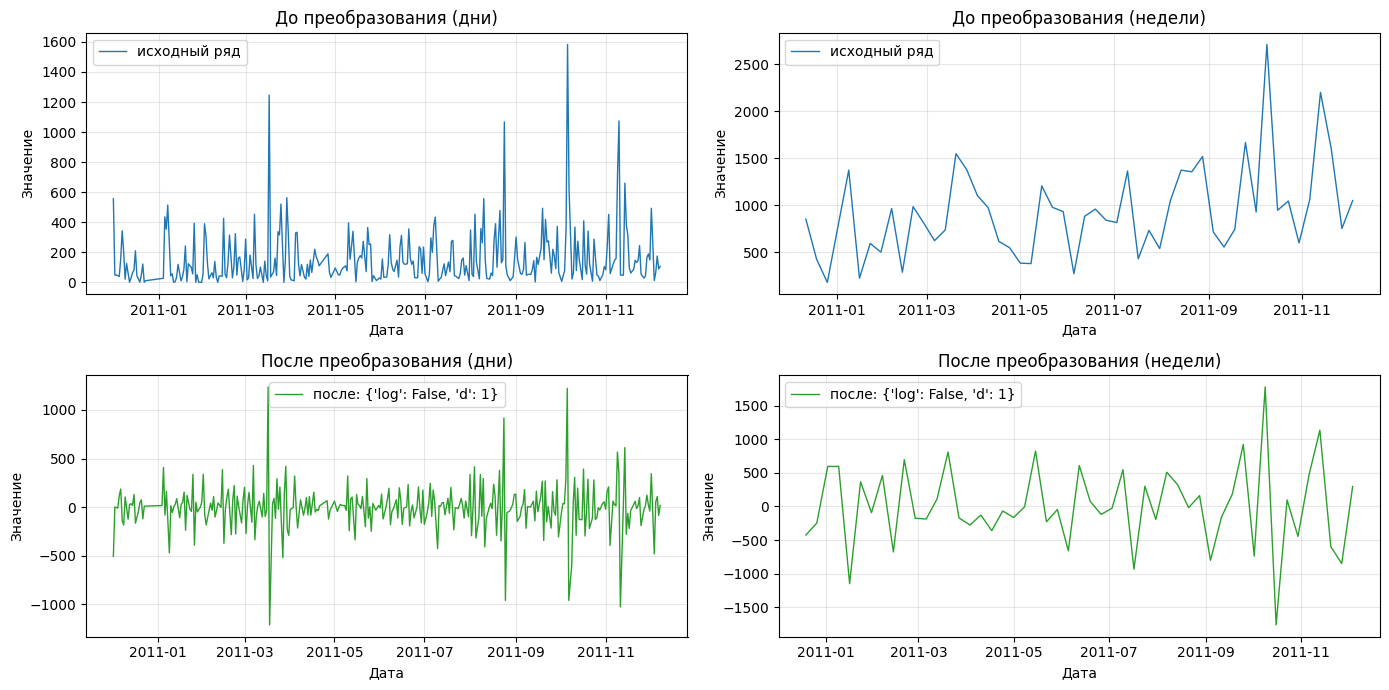

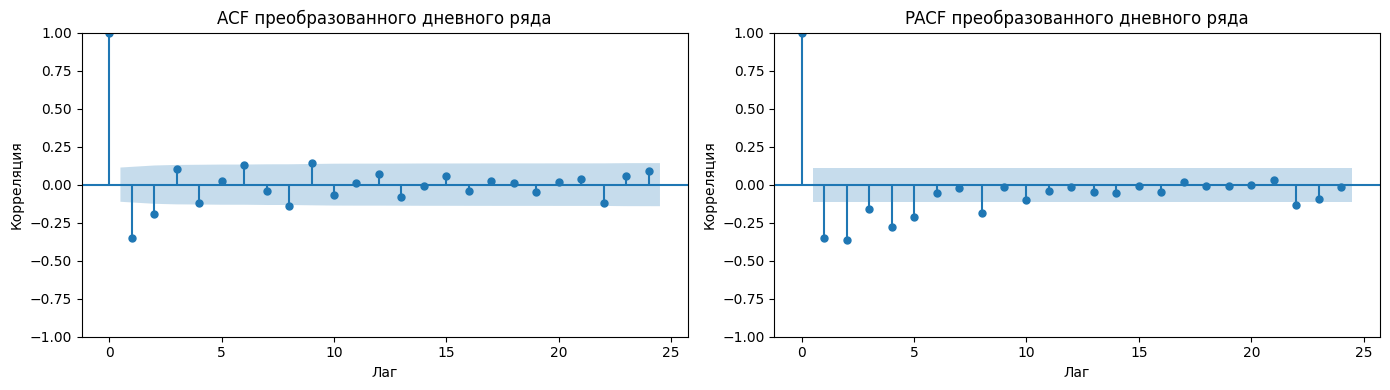

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for col, (s, z, name, used) in enumerate([(daily, daily_st, "дни", used_d), (weekly, weekly_st, "недели", used_w)]):
    axes[0, col].plot(s.index, s.values, lw=1, label="исходный ряд")
    axes[0, col].set_title(f"До преобразования ({name})")
    axes[1, col].plot(z.index, z.values, lw=1, c="tab:green", label=f"после: {used}")
    axes[1, col].set_title(f"После преобразования ({name})")
    for ax in axes[:, col]:
        ax.set_xlabel("Дата"); ax.set_ylabel("Значение"); ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
show("10_before_after")

T.plot_acf_pacf(daily_st, lags=3 * PERIOD_D + 6, suffix="преобразованного дневного ряда")
show("11_acf_after")

**Подбор преобразования.** Логарифм сам по себе не решает вопрос: расхождение тестов остаётся, а у дневного ряда после логарифма KPSS даже хуже (p = 0,010). Первая разность решает его и для дневного, и для недельного ряда, оба теста согласны. Дневной ряд: ADF -9,3 (p < 0,001), KPSS 0,096 (p не меньше 0,10). Недельный: ADF -3,2 (p = 0,021), KPSS 0,086 (p не меньше 0,10). Я взял первую разность без логарифма как самое простое преобразование, прошедшее оба теста. Для справки, log1p вместе с разностью тоже проходит оба теста, а для дневного ряда ещё и сезонная разность с лагом 6. Логарифм стоит добавить, если на моделировании понадобится убрать рост разброса: после разности он остаётся, осенью размах колебаний на графике заметно больше.

**Цена преобразования.** У исходного дневного ряда автокорреляция на лаге 1 была +0,16, а у разностного она стала -0,35 (на лаге 2 ещё -0,19), и PACF отрицательна на первых пяти лагах. Это типичный признак того, что ряд немного «переразностили»: разность вносит искусственную отрицательную автокорреляцию и добавляет шум. Поэтому формально преобразование выполнено и подтверждено тестами, но по разностному ряду нельзя судить о реальной динамике. Для прогнозной модели имеет смысл сравнить и более мягкие варианты, которые убирают только медленный уровень (вычитание сглаженного тренда, сезонная разность).

In [29]:
def pv(tab):
    return float(tab["p-value"].iloc[0]), float(tab["p-value"].iloc[1])

results.update(
    adf_d=pv(orig_tabs["дни (исходный)"][0]), verdict_d=orig_tabs["дни (исходный)"][1],
    adf_dw=pv(orig_tabs["дни (без экстремумов)"][0]), verdict_dw=orig_tabs["дни (без экстремумов)"][1],
    adf_w=pv(orig_tabs["недели"][0]), verdict_w=orig_tabs["недели"][1],
    used_d=used_d, used_w=used_w,
    adf_d2=pv(tab_d2), verdict_d2=v_d2, adf_w2=pv(tab_w2), verdict_w2=v_w2)

## Шаг 6. Функции и воспроизводимость

Все операции выше выполнены через функции из `src/ts_tools.py`: загрузка и отбор (`load_retail`, `select_product`), агрегация (`aggregate`, `drop_partial_edges`), пропуски (`missing_report`, `split_empty_days`, `to_trading_calendar`), выбросы (`iqr_outliers`, `mad_outliers`, `stl_residual_outliers`), описание (`describe_series`, `rolling_stats`, `trend_slope`), декомпозиция (`decompose`, `seasonal_strength`), стационарность (`stationarity_tests`, `make_stationary`, `choose_transformation`).

Ещё одна проверка: функция `build_series` проводит весь путь от транзакций до рядов за один вызов, и результат должен совпасть с тем, что мы собирали по шагам.

In [30]:
auto = T.build_series(df, STOCK)
print("дневной ряд совпадает:  ", auto["D"].equals(daily))
print("недельный ряд совпадает:", auto["W"].equals(weekly))
print("месячный ряд совпадает: ", auto["MS"].equals(monthly))
assert auto["D"].equals(daily) and auto["W"].equals(weekly) and auto["MS"].equals(monthly)

дневной ряд совпадает:   True
недельный ряд совпадает: True
месячный ряд совпадает:  True


## Шаг 7. Выводы

**Данные и ряд.** Товар 85099B (JUMBO BAG RED RETROSPOT), продажи в штуках без возвратов, с 1 декабря 2010 по 8 декабря 2011. Ряд получен в трёх частотах: 373 дня (304 после перехода на торговый календарь), 52 недели, 12 месяцев. Неполные периоды по краям отброшены.

**Качество данных.** Пустых дней 73 из 373, но 69 из них это дни, когда магазин не работал (53 субботы и 16 праздничных дней), поэтому нулями я их не заменял, а убрал из дневного ряда. Настоящих нулей 4. Недельная и месячная агрегации пропусков почти не имеют (одна неделя в рождественский перерыв, она интерполирована).

**Выбросы.** IQR отметил 14 точек, MAD 15, остаток STL 60 (слишком много, метод чувствителен к тяжёлому хвосту). Минимум два метода согласились на 15 днях. В трёх самых больших днях 63-96 % продаж даёт один круглый оптовый заказ в 1000-1200 штук. Выбросы не удалял: это фактические продажи. Для проверки устойчивости построил версию с ограничением сверху (751 штука, изменено 4 дня), на стационарности вывод не меняется.

**Описание.** Дневные продажи в среднем 159 штук при медиане 106, сильно скошены вправо (3,2), коэффициент вариации 1,19. С укрупнением периода ряд становится спокойнее (CV 0,52 по неделям и 0,33 по месяцам). Спрос «нерегулярный» (ADI 1,01, CV² 1,38): продаётся почти каждый день, но размер заказа сильно прыгает. Уровень растёт к осени (тренд по неделям +13 штук за неделю, p = 0,003), разброс растёт вместе с уровнем (корреляция среднего и std по неделям 0,77).

**Сезонность.** Недельная сезонность с периодом 6 торговых дней статистически значима (Краскел-Уоллис p близко к 0, воскресенье около 56 штук против четверга около 220), но слабая: сила сезонности STL 0,17, ACF на лаге 6 едва выше границы (0,12 при 0,112). Годовую сезонность оценить нельзя, данных чуть больше года, и рост к осени неотличим от тренда.

**Стационарность.** Исходный ряд: ADF отвергает единичный корень (p < 0,001), KPSS отвергает стационарность (p около 0,02), тесты расходятся, то есть стохастического тренда нет, но есть медленно растущий уровень. То же на ряду без экстремумов и на недельном. После первой разности оба теста согласны (дневной ряд: ADF p < 0,001, KPSS p ≥ 0,10; недельный: ADF p = 0,021, KPSS p ≥ 0,10). Минус: у разностного ряда появляется отрицательная автокорреляция на лаге 1 (-0,35), то есть он слегка переразностен.

**Ограничения.** Один год данных (нет годовой сезонности, тренд неотделим от осеннего роста); в месячном ряду 12 точек; не проверял, были ли крупные оптовые заказы позже отменены отдельными счетами-возвратами; тесты стационарности проводились с константой, без варианта с трендом.